# Stacking — predicción de `opinion` (componente de investigación)

Obligatorio MLSI 2026 S2. Esta notebook contiene:

1. Carga de datos
2. Preprocesamiento (código común en `obl_utils.py`)
3. Validación y métricas
4. Stacking: qué es, justificación y elección de los modelos base
5. Resultados: diversidad de los modelos base, desempeño del stacking y variantes
6. Comparación formal con el mejor modelo base (fold a fold)
7. Submission y resultado en Kaggle
8. Referencias

Como componente de investigación se elige el **Stacking Classifier** (*stacked generalization*): un ensamble que combina las predicciones de varios modelos de distinta naturaleza mediante un segundo modelo (meta-modelo) que aprende cómo ponderarlas. Los modelos base son los que ya se ajustaron en las notebooks anteriores, **con los mismos hiperparámetros elegidos allí**, y la evaluación usa la misma validación cruzada, así que la comparación con cada modelo por separado es directa.

## 1. Carga de datos

In [1]:
import os
import urllib.request

# El código común (preprocesamiento y evaluación) está en obl_utils.py.
# En Colab no está el archivo, así que se descarga del repo.
if not os.path.exists('obl_utils.py'):
    urllib.request.urlretrieve(
        'https://raw.githubusercontent.com/juanmareolon/OBL_ML/main/obl_utils.py', 'obl_utils.py')

import numpy as np
import pandas as pd
from obl_utils import *

# Carpetas de salida de esta notebook
CARPETA_RESULTADOS = 'resultados/Stacking'
CARPETA_KAGGLE = 'kaggle'
os.makedirs(CARPETA_RESULTADOS, exist_ok=True)
os.makedirs(CARPETA_KAGGLE, exist_ok=True)

train, test = cargar_datos()
X, y, X_test, ids_test = preparar_datos(train, test)

print('train:', train.shape, '| test:', test.shape)
print('X:', X.shape, '| X_test:', X_test.shape)
print('Balance de clases:', y.value_counts(normalize=True).round(3).to_dict())
X.head()

train: (3602, 14) | test: (1201, 14)
X: (3602, 15) | X_test: (1201, 15)
Balance de clases: {0: 0.506, 1: 0.494}


,budget_desconocido,log_budget,revenue_desconocido,log_revenue,log_roi,runtime,log_vote_count,log_popularity,anio,mes,sin_keywords,cant_keywords,main_genre_top10,original_language,director
0,0,18.064006,0,17.328879,0.391667,97.0,5.598422,2.657993,2002.0,10.0,0,8,Action,en,Betty Thomas
1,1,NaN,1,NaN,NaN,90.0,4.158883,1.767642,1992.0,5.0,0,4,Thriller,en,Tony Maylam
2,0,16.454568,0,15.446479,0.311093,90.0,4.234107,1.921864,2000.0,4.0,0,6,Drama,en,Davis Guggenheim
3,0,16.523561,0,18.384107,2.005155,96.0,6.928538,3.519225,2008.0,8.0,0,6,Drama,en,Woody Allen
4,0,19.336971,0,20.654943,1.555158,153.0,8.574329,4.604026,2009.0,7.0,0,7,Adventure,en,David Yates


## 2. Preprocesamiento

El código está en `obl_utils.py` y es el mismo para todas las notebooks de modelos. El motivo de cada decisión está detallado en `Arbol_Clasificacion.ipynb` (sección 2); acá va el resumen.

**Capa 1: limpieza fija (`limpiar`).** `budget` y `revenue` < 1000 pasan a NaN con indicador `*_desconocido`; `runtime` = 0 pasa a NaN; `log1p` de montos, votos y popularidad; variables nuevas `anio`, `mes`, `log_roi`, `sin_keywords` y `cant_keywords`.

**Capa 2: pipeline de sklearn (`crear_preprocesador`).** Imputación por mediana + `StandardScaler` en las numéricas, one-hot de `main_genre_top10` y `original_language` (idiomas con menos de 20 películas agrupados). `director` no se usa.

**En el stacking** el preprocesador se ajusta una sola vez por fold, con el train del fold, y las 27 columnas resultantes son la entrada de los cuatro modelos base. La estandarización es necesaria para la regresión logística y la red neuronal, y no les afecta a los modelos de árboles, así que un mismo preprocesamiento sirve para todos.

## 3. Validación y métricas

**Validación: k-fold cross-validation estratificado** (`crear_cv()`), con 5 folds y `SEED = 42`. Todos los modelos usan exactamente los mismos folds.

- Cada película se usa para validar exactamente una vez, a diferencia del holdout (depende de una sola división al azar) y del repeated holdout (algunas películas se validan varias veces y otras ninguna).
- *Estratificado*: cada fold mantiene la proporción de clases (51/49).
- El preprocesador va dentro de un `Pipeline` junto al modelo (`crear_pipeline()`), así medianas, escalas y encodings se ajustan solo con el train de cada fold (sin *data leakage*).

**Métricas** (`evaluar()`): accuracy, precision, recall, F1 y AUC-ROC, con promedio y desvío entre folds. También se registra el AUC en train: si es mucho mayor que el de validación, el modelo está sobreajustando. La matriz de confusión se obtiene con `matriz_confusion()`, usando las predicciones de validación de cada fold.

La métrica principal para elegir es el **AUC**, porque es la que usa la competencia de Kaggle.

**Particularidad del stacking: validación anidada.** El meta-modelo tiene que aprender con predicciones de los modelos base sobre películas que esos modelos **no vieron** al entrenar; si se usaran las predicciones sobre su propio train, el meta-modelo confiaría de más en los modelos que sobreajustan (por ejemplo, el Random Forest tiene AUC 0,96 en train). Por eso, dentro del train de cada fold de la CV se hace **otra** validación cruzada de 5 folds (sección 4.3). El fold de validación de la CV externa no se usa en ningún paso del entrenamiento, así que el AUC de validación sigue siendo una estimación honesta y comparable con la de los otros modelos.

## 4. Stacking

### 4.1 Qué es el stacking

El *stacking* o *stacked generalization* fue propuesto por Wolpert (1992) y formalizado para regresión por Breiman (1996). La idea es entrenar el modelo final en **dos niveles**:

1. **Nivel 0 (modelos base):** varios modelos distintos se entrenan con los mismos datos. Para cada película se obtiene, de cada modelo, la probabilidad de opinión positiva **predicha por un modelo que no la vio** (predicciones *out-of-fold*, obtenidas con validación cruzada).
2. **Nivel 1 (meta-modelo):** un segundo modelo recibe esas probabilidades como variables de entrada y aprende a combinarlas para predecir `opinion`.

Para predecir una película nueva, cada modelo base (reentrenado con todo el train) da su probabilidad y el meta-modelo las combina.

A diferencia del *bagging* (Random Forest) y del *boosting* (AdaBoost, Gradient Boosting), que combinan muchos modelos **del mismo tipo** con una regla fija (promedio o suma ponderada en secuencia), el stacking combina modelos **de distinto tipo** y **aprende** la regla de combinación a partir de los datos. Es una generalización del promedio de modelos: si el meta-modelo diera el mismo peso a todos, el stacking sería un promedio simple. Hastie, Tibshirani y Friedman (2009, sección 8.8) lo presentan justamente como una forma de elegir los pesos de un promedio de modelos usando predicciones *out-of-fold*, y van der Laan, Polley y Hubbard (2007) demostraron, bajo el nombre de *Super Learner*, que asintóticamente la combinación aprendida rinde al menos tan bien como el mejor de los modelos base.

### 4.2 Por qué puede mejorar y cuándo no

Un ensamble mejora a sus componentes solo si estos cometen **errores distintos**: si todos los modelos se equivocan en las mismas películas, combinarlos no agrega información (Kuncheva y Whitaker, 2003). Por eso la letra pide combinar modelos **de distinta naturaleza**, que aprenden la relación entre las variables y `opinion` de formas diferentes y, por lo tanto, tienden a equivocarse en casos distintos. La diversidad de los modelos elegidos se mide en la sección 5.2.

Al mismo tiempo, en las notebooks anteriores los mejores modelos quedaron muy cerca entre sí (AUC de validación entre 0,825 y 0,836, con desvíos de ~0,012) y usan las mismas 27 variables, así que es esperable que sus predicciones estén muy correlacionadas y que la ganancia del stacking, si existe, sea chica. La sección 6 compara formalmente si la mejora es real o está dentro del ruido de la validación.

### 4.3 Elección de los modelos base y del meta-modelo

**Modelos base** (con los hiperparámetros elegidos en cada notebook):

| Modelo | Naturaleza | Hiperparámetros | AUC val. (CV) |
|---|---|---|---|
| Regresión logística | Lineal: frontera de decisión lineal en las variables, estimada por máxima verosimilitud | `C=1`, L2 | 0,815 |
| Random Forest | *Bagging* de árboles profundos e independientes (reduce varianza) | 300 árboles, `max_depth=15`, `min_samples_leaf=5`, `max_features='sqrt'` | 0,825 |
| Gradient Boosting | *Boosting* de árboles chicos en secuencia, cada uno corrige el error de los anteriores (reduce sesgo) | 300 árboles, `max_depth=3`, `learning_rate=0.05`, `subsample=0.8` | 0,836 |
| Red neuronal (Keras) | Perceptrón multicapa: combinaciones no lineales y suaves de las variables, entrenado por descenso por gradiente | 128-64-32, `dropout=0.5`, `learning_rate=0.001`, early stopping | 0,832 |

Son cuatro familias distintas: un modelo **lineal**, dos ensambles de **árboles** que funcionan de manera opuesta (en paralelo e independientes contra en secuencia) y una **red neuronal**. Los árboles parten el espacio en rectángulos y capturan interacciones y umbrales; la logística y la red producen fronteras suaves, lineal en un caso y no lineal en el otro.

- **AdaBoost no se incluye** en la combinación principal porque es de la misma familia que Gradient Boosting (*boosting* de árboles de profundidad 3) y rinde menos (0,831), así que aportaría poca diversidad. Igual se prueba agregarlo en la sección 5.4.
- **El árbol de clasificación no se incluye** porque es el modelo más débil (0,769) y el Random Forest y el Gradient Boosting ya contienen árboles.

**Meta-modelo: regresión logística** (`C=1`, valores por defecto). Recibe 4 variables (la probabilidad de cada modelo base) y aprende un peso por modelo. Se elige un meta-modelo lineal y simple porque:

- Ting y Witten (1999) mostraron que el stacking funciona mejor cuando el nivel 1 recibe **probabilidades** (no la clase predicha) y el meta-modelo es **lineal**: un meta-modelo complejo tiende a sobreajustar, porque sus entradas están muy correlacionadas entre sí.
- Breiman (1996) recomienda restringir el combinador (pesos no negativos) por el mismo motivo; la regularización L2 de la logística cumple un rol parecido.
- Los pesos son interpretables: dicen cuánto aporta cada modelo base (sección 5.3).

Las probabilidades se pasan sin la variable original (`passthrough=False`): el meta-modelo solo combina modelos, no vuelve a aprender de las 27 variables.

### 4.4 Implementación

Se usa `StackingClassifier` de scikit-learn (Pedregosa et al., 2011), que implementa exactamente el procedimiento de la sección 4.1:

- `estimators`: los cuatro modelos base.
- `final_estimator`: el meta-modelo (regresión logística).
- `cv`: la validación interna con la que se obtienen las predicciones *out-of-fold* de cada modelo base. Se usa un k-fold estratificado de 5 folds con `SEED = 42`, igual que la CV principal.
- `stack_method='predict_proba'`: el meta-modelo recibe probabilidades.

Después de obtener las predicciones *out-of-fold*, `StackingClassifier` reentrena cada modelo base con todo el train recibido; esos modelos son los que predicen el test.

Para usar la red neuronal dentro del `StackingClassifier`, se reutiliza la clase `RedNeuronal` de `Red_Neuronal.ipynb`, que envuelve el modelo de Keras con la interfaz de un clasificador de sklearn (`fit`, `predict_proba`). Se copia sin cambios:

In [2]:
import os
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '3'  # oculta los mensajes informativos de TensorFlow

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.base import BaseEstimator, ClassifierMixin
from sklearn.model_selection import train_test_split

tf.get_logger().setLevel('ERROR')  # oculta avisos internos de TensorFlow (retracing)

import warnings
warnings.filterwarnings('ignore', message='A worker stopped')  # aviso de joblib al liberar procesos

print('TensorFlow', tf.__version__)


class RedNeuronal(ClassifierMixin, BaseEstimator):
    # Red neuronal de Keras con la interfaz de un clasificador de sklearn

    def __init__(self, capas=(64, 32), dropout=0.0, learning_rate=0.001, epocas=500, batch_size=32,
                 early_stopping=True, paciencia=30, random_state=SEED):
        self.capas = capas
        self.dropout = dropout
        self.learning_rate = learning_rate
        self.epocas = epocas
        self.batch_size = batch_size
        self.early_stopping = early_stopping
        self.paciencia = paciencia
        self.random_state = random_state

    def construir(self, n_variables):
        # Arquitectura: capas ocultas Dense con ReLU (+ Dropout) y una neurona de salida sigmoide
        modelo = keras.Sequential([keras.Input(shape=(n_variables,))])
        for neuronas in self.capas:
            modelo.add(layers.Dense(neuronas, activation='relu'))
            if self.dropout > 0:
                modelo.add(layers.Dropout(self.dropout))
        modelo.add(layers.Dense(1, activation='sigmoid'))
        modelo.compile(optimizer=keras.optimizers.Adam(learning_rate=self.learning_rate),
                       loss='binary_crossentropy', metrics=[keras.metrics.AUC(name='auc')])
        return modelo

    def fit(self, X, y, validation_data=None):
        X = np.asarray(X, dtype='float32')
        y = np.asarray(y, dtype='float32')
        keras.utils.set_random_seed(self.random_state)
        tf.get_logger().setLevel('ERROR')  # también en los procesos paralelos de la CV
        self.classes_ = np.array([0, 1])
        self.modelo_ = self.construir(X.shape[1])

        callbacks = []
        if self.early_stopping:
            # 15% del train (estratificado) reservado solo para decidir cuándo parar
            X, X_es, y, y_es = train_test_split(X, y, test_size=0.15, stratify=y,
                                                random_state=self.random_state)
            validation_data = (X_es, y_es)
            callbacks.append(keras.callbacks.EarlyStopping(monitor='val_loss', patience=self.paciencia,
                                                           restore_best_weights=True))

        historia = self.modelo_.fit(X, y, validation_data=validation_data, epochs=self.epocas,
                                    batch_size=self.batch_size, callbacks=callbacks, verbose=0)
        self.historia_ = historia.history
        self.epocas_entrenadas_ = len(historia.history['loss'])
        return self

    def predict_proba(self, X):
        p = self.modelo_.predict(np.asarray(X, dtype='float32'), batch_size=1024, verbose=0).ravel()
        return np.column_stack([1 - p, p])

    def predict(self, X):
        return (self.predict_proba(X)[:, 1] >= 0.5).astype(int)

TensorFlow 2.18.1


In [3]:
from sklearn.base import clone
from sklearn.ensemble import GradientBoostingClassifier, RandomForestClassifier, StackingClassifier
from sklearn.linear_model import LogisticRegression

# Modelos base con los hiperparámetros elegidos en cada notebook
MODELOS_BASE = {
    'Regresión logística': LogisticRegression(C=1, max_iter=1000, random_state=SEED),
    'Random Forest': RandomForestClassifier(n_estimators=300, max_depth=15, min_samples_leaf=5,
                                            max_features='sqrt', random_state=SEED),
    'Gradient Boosting': GradientBoostingClassifier(n_estimators=300, max_depth=3, learning_rate=0.05,
                                                    subsample=0.8, random_state=SEED),
    'Red neuronal': RedNeuronal(capas=(128, 64, 32), dropout=0.5, learning_rate=0.001),
}
NOMBRES_CORTOS = {'Regresión logística': 'logistica', 'Random Forest': 'rf',
                  'Gradient Boosting': 'gb', 'Red neuronal': 'red'}

def crear_stacking(modelos_base=MODELOS_BASE):
    return StackingClassifier(
        estimators=[(NOMBRES_CORTOS[n], clone(m)) for n, m in modelos_base.items()],
        final_estimator=LogisticRegression(C=1, max_iter=1000),
        cv=crear_cv(),                 # CV interna: k-fold estratificado de 5 folds, SEED = 42
        stack_method='predict_proba',
        passthrough=False,
    )

stacking = crear_stacking()
stacking

StackingClassifier(cv=StratifiedKFold(n_splits=5, random_state=42, shuffle=True),
                   estimators=[('logistica',
                                LogisticRegression(C=1, max_iter=1000,
                                                   random_state=42)),
                               ('rf',
                                RandomForestClassifier(max_depth=15,
                                                       min_samples_leaf=5,
                                                       n_estimators=300,
                                                       random_state=42)),
                               ('gb',
                                GradientBoostingClassifier(learning_rate=0.05,
                                                           n_estimators=300,
                                                           random_state=42,
                                                           subsample=0.8)),
                               ('red',
                                RedNeuronal(capas=(128, 64, 32), dropout=0.5))],
                   final_estimator=LogisticRegression(C=1, max_iter=1000),
                   stack_method='predict_proba')

## 5. Resultados

### 5.1 Predicciones de los modelos base en cada fold

Para analizar el stacking por dentro (diversidad de los modelos, pesos del meta-modelo, variantes con otros modelos base) se reproduce paso a paso lo que hace `StackingClassifier` en cada fold de la CV externa, y se guardan las predicciones intermedias:

1. Se ajusta el preprocesador con el train del fold.
2. Para cada modelo base se obtienen sus predicciones *out-of-fold* sobre el train del fold con la CV interna (`cross_val_predict`): son las variables de entrada con las que se entrena el meta-modelo.
3. Cada modelo base se reentrena con todo el train del fold y predice el fold de validación: son las entradas del meta-modelo al predecir.

Así, cada combinación de modelos base y cada meta-modelo se evalúan sin volver a entrenar los modelos base. Se agrega **AdaBoost** (con sus hiperparámetros elegidos) solo para probarlo como quinto modelo en la sección 5.4. Los 5 folds se procesan en paralelo.

In [4]:
import time
from joblib import Parallel, delayed
from sklearn.ensemble import AdaBoostClassifier
from sklearn.metrics import roc_auc_score
from sklearn.model_selection import cross_val_predict
from sklearn.tree import DecisionTreeClassifier

MODELOS_ANALISIS = {**MODELOS_BASE,
                    'AdaBoost': AdaBoostClassifier(DecisionTreeClassifier(max_depth=3, random_state=SEED),
                                                   n_estimators=500, learning_rate=0.5, random_state=SEED)}

def predicciones_fold(idx_train, idx_val):
    # Lo mismo que hace StackingClassifier dentro de un fold de la CV externa, guardando las predicciones
    prep = crear_preprocesador().fit(X.iloc[idx_train], y.iloc[idx_train])
    X_tr, X_val = prep.transform(X.iloc[idx_train]), prep.transform(X.iloc[idx_val])
    y_tr = y.iloc[idx_train].to_numpy()
    oof, val = {}, {}
    for nombre, modelo in MODELOS_ANALISIS.items():
        # entradas del meta-modelo al entrenar: predicciones out-of-fold de la CV interna
        oof[nombre] = cross_val_predict(clone(modelo), X_tr, y_tr, cv=crear_cv(), method='predict_proba')[:, 1]
        # entradas del meta-modelo al predecir: modelo base reentrenado con todo el train del fold
        val[nombre] = clone(modelo).fit(X_tr, y_tr).predict_proba(X_val)[:, 1]
    return {'idx_train': idx_train, 'idx_val': idx_val, 'oof': pd.DataFrame(oof), 'val': pd.DataFrame(val)}

inicio = time.time()
folds = Parallel(n_jobs=-1)(delayed(predicciones_fold)(tr, va) for tr, va in crear_cv().split(X, y))
print(f'Predicciones de {len(MODELOS_ANALISIS)} modelos en {N_FOLDS} folds: {(time.time() - inicio) / 60:.1f} min')

# AUC de validación de cada modelo base en cada fold
auc_bases = pd.DataFrame(
    {n: [roc_auc_score(y.iloc[f['idx_val']], f['val'][n]) for f in folds] for n in MODELOS_ANALISIS},
    index=[f'fold {i}' for i in range(1, N_FOLDS + 1)])
auc_bases.loc['promedio'] = auc_bases.mean()
auc_bases.loc['desvío'] = auc_bases.iloc[:N_FOLDS].std(ddof=0)
auc_bases.round(3)

Predicciones de 5 modelos en 5 folds: 5.0 min


,Regresión logística,Random Forest,Gradient Boosting,Red neuronal,AdaBoost
fold 1,0.814,0.816,0.846,0.831,0.845
fold 2,0.820,0.838,0.843,0.826,0.832
fold 3,0.827,0.837,0.847,0.849,0.843
fold 4,0.800,0.810,0.815,0.817,0.813
fold 5,0.817,0.822,0.824,0.839,0.820
promedio,0.815,0.824,0.835,0.832,0.831
desvío,0.009,0.011,0.013,0.011,0.013


Los AUC de validación de cada modelo base coinciden con los obtenidos en su notebook (regresión logística 0,815, Random Forest 0,825, red neuronal 0,832, AdaBoost 0,831; Gradient Boosting da 0,835 contra 0,836, una diferencia menor a 0,001 que no cambia ninguna conclusión), lo que confirma que se están combinando exactamente los modelos ya elegidos y con los mismos folds. El fold 4 es el más difícil para todos los modelos.

### 5.2 Diversidad de los modelos base

Se mide qué tan parecidas son las predicciones de los modelos base con la **correlación de Spearman** entre sus probabilidades sobre las películas de validación (las 3602, juntando los 5 folds). Se usa Spearman porque el AUC solo depende del orden de las probabilidades, no de su escala: dos modelos con correlación de Spearman 1 ordenan las películas igual y tienen el mismo AUC, aunque sus probabilidades sean distintas.

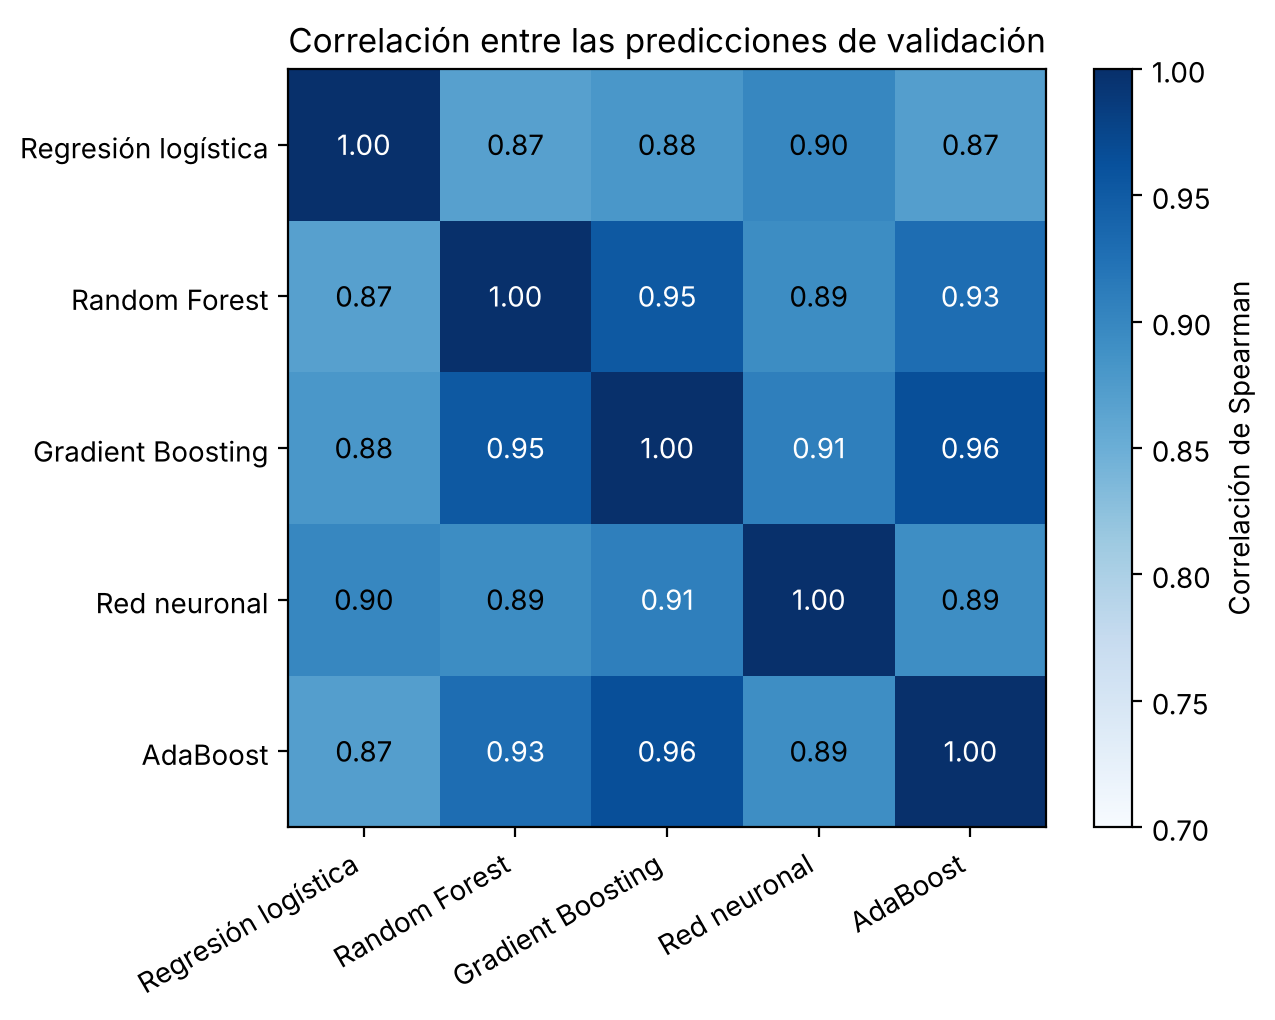

In [5]:
import matplotlib.pyplot as plt

pred_val = pd.concat([f['val'] for f in folds], ignore_index=True)
correlaciones = pred_val.corr(method='spearman')

fig, ax = plt.subplots(figsize=(6.5, 5.2))
im = ax.imshow(correlaciones, cmap='Blues', vmin=0.7, vmax=1)
nombres = list(correlaciones.columns)
ax.set_xticks(range(len(nombres)), nombres, rotation=30, ha='right')
ax.set_yticks(range(len(nombres)), nombres)
for i in range(len(nombres)):
    for j in range(len(nombres)):
        v = correlaciones.iloc[i, j]
        ax.text(j, i, f'{v:.2f}', ha='center', va='center', color='white' if v > 0.9 else 'black')
fig.colorbar(im, ax=ax, label='Correlación de Spearman')
ax.set_title('Correlación entre las predicciones de validación')
plt.tight_layout()
plt.show()

**Lectura:**

- Todas las correlaciones son altas (entre 0,87 y 0,96): los modelos usan las mismas variables y coinciden en qué películas son fáciles de clasificar. Por eso no se espera una mejora grande del stacking.
- Los pares **más parecidos** son los de árboles: Gradient Boosting con AdaBoost (0,96) y con Random Forest (0,95). Esto confirma que AdaBoost aporta poca diversidad respecto de Gradient Boosting.
- Los modelos **más distintos** de los ensambles de árboles son la regresión logística (0,87–0,88) y la red neuronal (0,89–0,91): producen fronteras de decisión suaves en lugar de cortes por umbrales, y se equivocan en películas en parte diferentes. Son los que pueden aportar información nueva al combinarlos con Gradient Boosting.

### 5.3 Desempeño del stacking

Se evalúa el stacking principal (logística + Random Forest + Gradient Boosting + red neuronal, meta-modelo logístico) y, como referencia, el **promedio simple** de las probabilidades de los mismos cuatro modelos (*soft voting*): si el stacking no supera al promedio simple, aprender los pesos no aporta nada.

In [6]:
PRINCIPAL = list(MODELOS_BASE)
META = LogisticRegression(C=1, max_iter=1000)

def evaluar_combinacion(modelos, meta=META):
    # AUC de validación por fold del stacking y del promedio simple con los modelos base indicados,
    # usando las predicciones guardadas en la sección 5.1. Devuelve también los pesos del meta-modelo.
    auc_stack, auc_prom, pesos = [], [], []
    for f in folds:
        y_tr, y_val = y.iloc[f['idx_train']], y.iloc[f['idx_val']]
        m = clone(meta).fit(f['oof'][modelos], y_tr)
        auc_stack.append(roc_auc_score(y_val, m.predict_proba(f['val'][modelos])[:, 1]))
        auc_prom.append(roc_auc_score(y_val, f['val'][modelos].mean(axis=1)))
        pesos.append(m.coef_[0])
    return np.array(auc_stack), np.array(auc_prom), pd.DataFrame(pesos, columns=modelos)

auc_stack, auc_prom, pesos = evaluar_combinacion(PRINCIPAL)
mejor_base = auc_bases.loc['promedio', PRINCIPAL].idxmax()

resumen = pd.DataFrame({
    'AUC val.': [auc_stack.mean(), auc_prom.mean()] + [auc_bases.loc['promedio', n] for n in PRINCIPAL],
    'desvío': [auc_stack.std(), auc_prom.std()] + [auc_bases.loc['desvío', n] for n in PRINCIPAL],
}, index=['Stacking (meta-modelo logístico)', 'Promedio simple de los 4'] + PRINCIPAL)
print(f'Mejor modelo base: {mejor_base}')
resumen.sort_values('AUC val.', ascending=False).round(4)

Mejor modelo base: Gradient Boosting


,AUC val.,desvío
Stacking (meta-modelo logístico),0.8400,0.0098
Promedio simple de los 4,0.8394,0.0096
Gradient Boosting,0.8350,0.0131
Red neuronal,0.8324,0.0109
Random Forest,0.8245,0.0113
Regresión logística,0.8155,0.0087


**Lectura:**

- El stacking obtiene un **AUC de validación de 0,840 ± 0,010**, el mayor de todos los modelos del obligatorio: 0,005 más que Gradient Boosting (0,835), 0,008 más que la red neuronal, 0,016 más que el Random Forest y 0,025 más que la regresión logística.
- Además tiene un **desvío entre folds menor** (0,010 contra 0,013 de Gradient Boosting): al promediar modelos que se equivocan en casos distintos, el resultado depende menos del fold.
- El **promedio simple** de los cuatro modelos obtiene casi lo mismo (0,839). Es decir, casi toda la ganancia viene de **combinar** modelos distintos y muy poco de **aprender los pesos**: con cuatro modelos de rendimiento parecido, el promedio con pesos iguales ya es una muy buena combinación, algo que también se observa en la literatura (Hastie et al., 2009, sección 8.8).

**Pesos del meta-modelo.** Coeficientes de la regresión logística de nivel 1 en cada fold (cada modelo base es una variable de entrada, en la escala de probabilidad 0 a 1):

In [7]:
pesos.index = [f'fold {i}' for i in range(1, N_FOLDS + 1)]
pesos.loc['promedio'] = pesos.mean()
pesos.loc['desvío'] = pesos.iloc[:N_FOLDS].std(ddof=0)
pesos.round(2)

,Regresión logística,Random Forest,Gradient Boosting,Red neuronal
fold 1,0.91,1.14,1.57,2.08
fold 2,0.55,0.74,2.04,2.34
fold 3,0.64,0.44,2.71,1.81
fold 4,0.56,1.05,1.81,2.35
fold 5,0.43,0.53,2.85,1.83
promedio,0.62,0.78,2.20,2.08
desvío,0.16,0.28,0.50,0.23


**Lectura:**

- Los cuatro pesos son **positivos** en todos los folds: el meta-modelo usa los cuatro modelos y ninguno resta.
- Los mayores pesos son los de **Gradient Boosting (2,20)** y la **red neuronal (2,08)**, los dos mejores modelos base y, a la vez, los dos de naturaleza más distinta entre los fuertes (árboles en secuencia contra red). El Random Forest (0,78) y la regresión logística (0,62) aportan menos: el Random Forest se parece mucho a Gradient Boosting (correlación 0,95) y la logística es el modelo más débil.
- Los pesos varían bastante entre folds (por ejemplo, Gradient Boosting entre 1,57 y 2,85) porque las entradas están muy correlacionadas: hay muchas combinaciones de pesos que predicen casi igual. Por eso los pesos sirven para ver qué modelos aportan más, pero no deben leerse con mucha precisión.

### 5.4 Variantes: otras combinaciones de modelos base

Para ver si la elección de los modelos base es razonable, se evalúan otras combinaciones con el mismo meta-modelo. Son un análisis de sensibilidad: la combinación principal se eligió antes, por la naturaleza de los modelos (sección 4.3), y no se cambia según estos resultados, porque elegir entre muchas combinaciones con los mismos folds favorecería a la que tuvo suerte en esos folds.

In [8]:
COMBINACIONES = {
    'Principal: logística + RF + GB + red': PRINCIPAL,
    'Principal + AdaBoost (5 modelos)': PRINCIPAL + ['AdaBoost'],
    'Sin red: logística + RF + GB': ['Regresión logística', 'Random Forest', 'Gradient Boosting'],
    'Sin RF: logística + GB + red': ['Regresión logística', 'Gradient Boosting', 'Red neuronal'],
    'Sin logística: RF + GB + red': ['Random Forest', 'Gradient Boosting', 'Red neuronal'],
    'Sin GB: logística + RF + red': ['Regresión logística', 'Random Forest', 'Red neuronal'],
    'Solo árboles: RF + GB + AdaBoost': ['Random Forest', 'Gradient Boosting', 'AdaBoost'],
}
filas = []
for nombre, modelos in COMBINACIONES.items():
    a_stack, a_prom, _ = evaluar_combinacion(modelos)
    gb = auc_bases['Gradient Boosting'].iloc[:N_FOLDS].to_numpy()
    filas.append({'combinación': nombre, 'modelos': len(modelos),
                  'AUC stacking': a_stack.mean(), 'desvío': a_stack.std(),
                  'AUC promedio simple': a_prom.mean(),
                  'dif. vs GB': (a_stack - gb).mean(), 'folds que gana a GB': int((a_stack > gb).sum())})
variantes = pd.DataFrame(filas).set_index('combinación')
variantes.to_csv(f'{CARPETA_RESULTADOS}/stacking_variantes.csv')
variantes.round(4)

,modelos,AUC stacking,desvío,AUC promedio simple,dif. vs GB,folds que gana a GB
combinación,,,,,,
Principal: logística + RF + GB + red,4,0.8400,0.0098,0.8394,0.0050,4
Principal + AdaBoost (5 modelos),5,0.8405,0.0095,0.8399,0.0055,4
Sin red: logística + RF + GB,3,0.8366,0.0109,0.8360,0.0016,4
Sin RF: logística + GB + red,3,0.8406,0.0099,0.8394,0.0056,3
Sin logística: RF + GB + red,3,0.8403,0.0100,0.8401,0.0053,4
Sin GB: logística + RF + red,3,0.8373,0.0098,0.8361,0.0023,3
Solo árboles: RF + GB + AdaBoost,3,0.8355,0.0116,0.8351,0.0005,4


**Lectura:**

- **La red neuronal es el componente que más aporta.** Sin ella, el stacking baja de 0,840 a 0,837, y la combinación de solo árboles (RF + GB + AdaBoost) queda en 0,836, igual que Gradient Boosting solo: combinar árboles con árboles no agrega información. La mejora aparece al combinar los árboles con un modelo de naturaleza distinta.
- Sacar el Random Forest o la regresión logística casi no cambia el resultado (0,841 y 0,840): sus predicciones ya están cubiertas por Gradient Boosting y la red. Sacar Gradient Boosting sí baja el AUC (0,837).
- Agregar AdaBoost como quinto modelo no mejora (0,8405 contra 0,8400), como anticipaba su correlación de 0,96 con Gradient Boosting.
- Todas las combinaciones de **tres o más modelos de naturaleza distinta** quedan entre 0,840 y 0,841, y en todas el promedio simple da casi lo mismo que el meta-modelo. Las diferencias entre ellas (≤ 0,001) son mucho menores que el desvío, así que se mantiene la combinación principal, elegida de antemano.

### 5.5 Evaluación con `StackingClassifier`

Por último, se evalúa el stacking principal con `StackingClassifier` y la función `evaluar` de `obl_utils.py`, igual que todos los modelos anteriores, para obtener todas las métricas (accuracy, precision, recall, F1 y AUC en train). Como el procedimiento y las semillas son los mismos, el AUC de validación de cada fold tiene que coincidir con el de la sección 5.3.

In [9]:
from sklearn.model_selection import cross_validate

inicio = time.time()
resultado_stacking = evaluar(stacking, X, y, modelos_base='logistica + rf + gb + red', meta_modelo='logistica')
cv_stacking = cross_validate(crear_pipeline(stacking), X, y, cv=crear_cv(), scoring='roc_auc', n_jobs=-1)
print(f'Tiempo: {(time.time() - inicio) / 60:.1f} min')
print('Diferencia máxima con la sección 5.3 (por fold):',
      f"{np.abs(cv_stacking['test_score'] - auc_stack).max():.6f}")
pd.DataFrame([resultado_stacking]).drop(columns=['director']).round(3)

Tiempo: 8.0 min
Diferencia máxima con la sección 5.3 (por fold): 0.000000


,modelo,modelos_base,meta_modelo,accuracy,accuracy_std,precision,precision_std,recall,recall_std,f1,f1_std,auc,auc_std,auc_train
0,StackingClassifier,logistica + rf + gb + red,logistica,0.755,0.011,0.777,0.015,0.706,0.021,0.74,0.013,0.84,0.01,0.914


El AUC de validación de cada fold coincide exactamente con el de la sección 5.3 (diferencia máxima 0), así que el análisis paso a paso reproduce fielmente al `StackingClassifier`.

El stacking obtiene **0,840 ± 0,010 de AUC en validación, con 0,914 en train**. La diferencia entre train y validación (0,074) es menor que la de Gradient Boosting (0,090) y mucho menor que la del Random Forest (0,136): el meta-modelo, al entrenarse con predicciones *out-of-fold*, no hereda el sobreajuste de los modelos base. En las métricas con umbral de 0,5 queda igual o apenas por encima de Gradient Boosting (accuracy 0,755 contra 0,752, precision 0,777 contra 0,766, recall 0,706 contra 0,715, F1 0,740 en ambos).

## 6. Comparación formal con el mejor modelo base

La pregunta de la investigación es si el stacking **mejora** al mejor modelo por separado, Gradient Boosting. Como todos los modelos se evaluaron con **los mismos 5 folds**, la comparación correcta es **pareada**: se mira la diferencia de AUC fold a fold, que elimina la variación debida a que algunos folds son más difíciles que otros para todos los modelos.

Se usan dos criterios:

1. **Cantidad de folds en que gana el stacking** y tamaño de la diferencia.
2. **Test t pareado corregido** de Nadeau y Bengio (2003). El test t pareado común supone que las diferencias de los folds son independientes, pero no lo son: cada par de folds comparte el 75% de las películas de entrenamiento, y por eso el test común da p-valores demasiado chicos, es decir, encuentra diferencias que no existen (Dietterich, 1998). La corrección de Nadeau y Bengio agranda la varianza de la media para tener en cuenta esa dependencia:

$$t = \frac{\bar d}{\sqrt{\left(\frac{1}{k} + \frac{n_{val}}{n_{train}}\right) s_d^2}}$$

donde $\bar d$ y $s_d^2$ son la media y la varianza muestral de las diferencias, $k = 5$ folds y $n_{val}/n_{train} = 1/4$. Se compara con una t de Student de $k - 1 = 4$ grados de libertad. Se muestra también el test t común como referencia. La hipótesis nula es que el stacking y Gradient Boosting tienen el mismo AUC esperado.

In [10]:
from scipy import stats

def test_t_corregido(dif, n_train, n_val):
    # Test t pareado con la corrección de varianza de Nadeau y Bengio (2003), bilateral
    k = len(dif)
    t = dif.mean() / np.sqrt((1 / k + n_val / n_train) * dif.var(ddof=1))
    return t, 2 * stats.t.sf(abs(t), df=k - 1)

auc_por_fold = auc_bases.iloc[:N_FOLDS][PRINCIPAL].copy()
auc_por_fold['Stacking'] = cv_stacking['test_score']
filas = []
for base in PRINCIPAL:
    dif = auc_por_fold['Stacking'].to_numpy() - auc_por_fold[base].to_numpy()
    t_c, p_c = test_t_corregido(dif, n_train=len(X) * (N_FOLDS - 1) / N_FOLDS, n_val=len(X) / N_FOLDS)
    t_n, p_n = stats.ttest_rel(auc_por_fold['Stacking'], auc_por_fold[base])
    filas.append({'Stacking vs': base, 'dif. media': dif.mean(), 'dif. mín.': dif.min(), 'dif. máx.': dif.max(),
                  'folds que gana': f'{(dif > 0).sum()} de {N_FOLDS}',
                  't corregido': t_c, 'p corregido': p_c, 'p sin corregir': p_n})
comparacion_formal = pd.DataFrame(filas).set_index('Stacking vs')

auc_por_fold['dif. vs GB'] = auc_por_fold['Stacking'] - auc_por_fold['Gradient Boosting']
auc_por_fold.to_csv(f'{CARPETA_RESULTADOS}/stacking_auc_por_fold.csv')
comparacion_formal.to_csv(f'{CARPETA_RESULTADOS}/stacking_comparacion_formal.csv')
display(auc_por_fold.round(4))
comparacion_formal.round(4)

,Regresión logística,Random Forest,Gradient Boosting,Red neuronal,Stacking,dif. vs GB
fold 1,0.8137,0.8157,0.8461,0.8310,0.8411,-0.0050
fold 2,0.8196,0.8376,0.8430,0.8259,0.8433,0.0003
fold 3,0.8267,0.8375,0.8468,0.8491,0.8543,0.0075
fold 4,0.8004,0.8099,0.8146,0.8172,0.8240,0.0095
fold 5,0.8171,0.8217,0.8244,0.8386,0.8373,0.0129


,dif. media,dif. mín.,dif. máx.,folds que gana,t corregido,p corregido,p sin corregir
Stacking vs,,,,,,,
Regresión logística,0.0245,0.0202,0.0276,5 de 5,11.8897,0.0003,0.0001
Random Forest,0.0155,0.0057,0.0254,5 de 5,3.2969,0.0300,0.0078
Gradient Boosting,0.0050,-0.0050,0.0129,4 de 5,1.0358,0.3588,0.1952
Red neuronal,0.0077,-0.0013,0.0174,4 de 5,1.6614,0.1720,0.0673


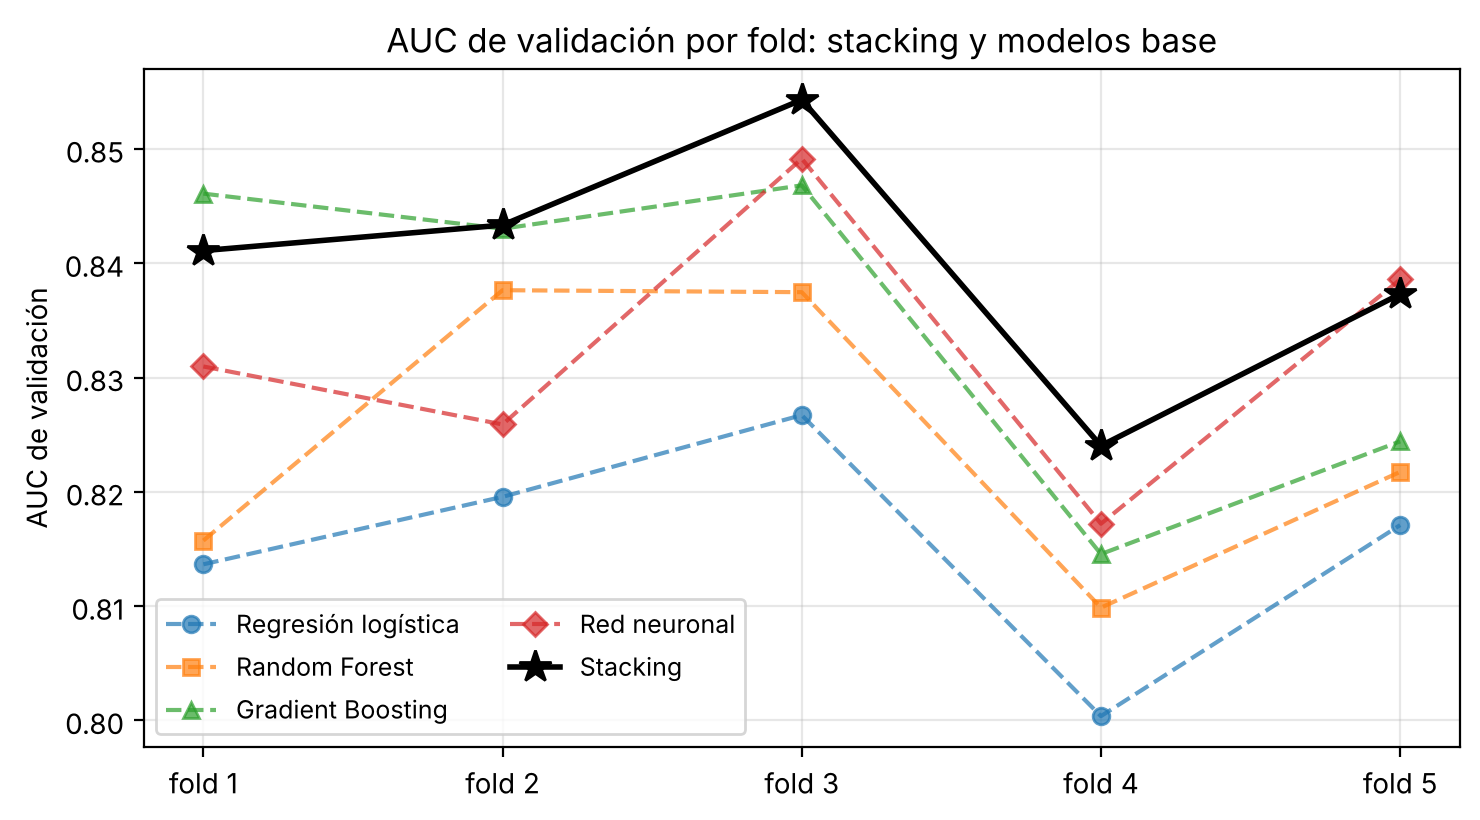

In [11]:
fig, ax = plt.subplots(figsize=(7.5, 4.2))
x = np.arange(1, N_FOLDS + 1)
for base, marcador in zip(PRINCIPAL, ['o', 's', '^', 'D']):
    ax.plot(x, auc_por_fold[base], marker=marcador, linestyle='--', alpha=0.7, label=base)
ax.plot(x, auc_por_fold['Stacking'], marker='*', markersize=12, color='black', linewidth=2, label='Stacking')
ax.set_xticks(x, [f'fold {i}' for i in x])
ax.set_ylabel('AUC de validación')
ax.set_title('AUC de validación por fold: stacking y modelos base')
ax.legend(fontsize=9, ncol=2)
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

**Lectura:**

- **Contra Gradient Boosting (el mejor modelo base):** el stacking gana en 4 de los 5 folds, con una diferencia media de **+0,005** (entre −0,005 en el fold 1 y +0,013 en el fold 5). El test t corregido da **p = 0,36**: la mejora **no es estadísticamente significativa**. Incluso el test sin corregir, que es demasiado optimista, da p = 0,20. Con 5 folds y diferencias de este tamaño, no se puede descartar que la ventaja se deba a la variabilidad de la validación.
- **Contra la red neuronal:** gana en 4 de 5 folds (+0,008), tampoco significativo (p = 0,17).
- **Contra el Random Forest y la regresión logística:** gana en los 5 folds, con diferencias significativas (p = 0,030 y p = 0,0003 con el test corregido).
- El gráfico muestra que el stacking queda arriba o muy cerca del mejor modelo de cada fold, aunque el mejor modelo base cambia de un fold a otro (Gradient Boosting en los folds 1, 2 y 4, la red en los folds 3 y 5). Esa es la ventaja práctica del stacking: no depende de acertar cuál es el mejor modelo, y por eso su desvío entre folds es el menor.

**Conclusión de la comparación:** el stacking es el modelo con mayor AUC de validación (0,840) y el más estable entre folds, pero su ventaja sobre Gradient Boosting (+0,005) es chica y no significativa. Se confirma lo anticipado en la sección 4.2: los modelos base están muy correlacionados (0,87 a 0,96), así que combinarlos aporta poco. La mejora existe solo cuando se combinan modelos de distinta naturaleza (árboles y red neuronal); con modelos de la misma familia desaparece.

**Comparación con todos los modelos del obligatorio:**

In [12]:
def leer_final(ruta):
    # En Colab no está la carpeta resultados: se lee del repo
    if not os.path.exists(ruta):
        ruta = 'https://raw.githubusercontent.com/juanmareolon/OBL_ML/main/' + ruta
    return pd.read_csv(ruta).iloc[0]

COLS = ['modelo', 'auc_cv', 'auc_cv_std', 'auc_train', 'accuracy', 'precision', 'recall', 'f1', 'auc_kaggle']
filas = [{'modelo': 'Stacking', 'auc_cv': resultado_stacking['auc'], 'auc_cv_std': resultado_stacking['auc_std'],
          'auc_train': resultado_stacking['auc_train'], 'accuracy': resultado_stacking['accuracy'],
          'precision': resultado_stacking['precision'], 'recall': resultado_stacking['recall'],
          'f1': resultado_stacking['f1'], 'auc_kaggle': np.nan}]
for ruta in ['resultados/Arbol_Clasificacion/arbol_final.csv',
             'resultados/Regresion_Logistica/logistica_final.csv',
             'resultados/Random_Forest/random_forest_final.csv',
             'resultados/Boosting/adaboost_final.csv',
             'resultados/Boosting/gradient_boosting_final.csv',
             'resultados/Red_Neuronal/red_neuronal_final.csv']:
    r = leer_final(ruta)
    filas.append({c: r[c] for c in COLS})

comparacion_modelos = pd.DataFrame(filas).set_index('modelo').sort_values('auc_cv', ascending=False)
comparacion_modelos.round(3)

,auc_cv,auc_cv_std,auc_train,accuracy,precision,recall,f1,auc_kaggle
modelo,,,,,,,,
Stacking,0.840,0.010,0.914,0.755,0.777,0.706,0.740,NaN
Gradient Boosting,0.836,0.013,0.926,0.752,0.766,0.715,0.740,0.841
Red neuronal,0.832,0.011,0.871,0.748,0.803,0.650,0.717,0.837
AdaBoost,0.831,0.013,0.892,0.751,0.763,0.719,0.740,0.834
Random Forest,0.825,0.011,0.960,0.743,0.761,0.698,0.728,0.844
Regresión logística,0.815,0.009,0.821,0.744,0.751,0.721,0.736,0.819
Árbol de clasificación,0.769,0.013,0.813,0.697,0.705,0.669,0.685,0.771


## 7. Submission y resultado en Kaggle

Se entrena el stacking con **todo** el train (preprocesador, los cuatro modelos base con la CV interna y el meta-modelo) y se guardan las **probabilidades** de la clase 1 para las 1201 películas del test.

In [13]:
sub = generar_submission(stacking, X, y, X_test, ids_test, f'{CARPETA_KAGGLE}/submission_stacking.csv')

# Chequeos: 1201 filas, sin NaN y probabilidades (no solo 0/1)
assert len(sub) == len(X_test) and sub['opinion'].notna().all()
print(f"Probabilidades entre {sub['opinion'].min():.3f} y {sub['opinion'].max():.3f}, "
      f"{sub['opinion'].nunique()} valores distintos")
sub.head()

Guardado kaggle/submission_stacking.csv (1201 filas)
Probabilidades entre 0.064 y 0.952, 1201 valores distintos


,id,opinion
0,0,0.943792
1,1,0.216097
2,2,0.775206
3,3,0.932120
4,4,0.728887


### Resultado en Kaggle

*Public Score* obtenido al subir `kaggle/submission_stacking.csv`. La fila se guarda en `resultados/Stacking/stacking_final.csv` para la tabla comparativa entre modelos.

In [14]:
auc_kaggle = 0.84568  # Public Score de submission_stacking.csv

resultado_final = {
    'modelo': 'Stacking',
    'hiperparametros': ('base: logistica (C=1) + random forest (300, depth 15, leaf 5, sqrt) + '
                        'gradient boosting (300, depth 3, lr 0.05, subsample 0.8) + red (128-64-32, dropout 0.5); '
                        'meta: logistica (C=1); cv interna 5 folds'),
    'auc_cv': resultado_stacking['auc'], 'auc_cv_std': resultado_stacking['auc_std'],
    'auc_train': resultado_stacking['auc_train'], 'accuracy': resultado_stacking['accuracy'],
    'precision': resultado_stacking['precision'], 'recall': resultado_stacking['recall'],
    'f1': resultado_stacking['f1'], 'auc_kaggle': auc_kaggle,
}
pd.DataFrame([resultado_final]).to_csv(f'{CARPETA_RESULTADOS}/stacking_final.csv', index=False)
pd.set_option('display.max_colwidth', None)
pd.DataFrame([resultado_final]).round(3)

,modelo,hiperparametros,auc_cv,auc_cv_std,auc_train,accuracy,precision,recall,f1,auc_kaggle
0,Stacking,"base: logistica (C=1) + random forest (300, depth 15, leaf 5, sqrt) + gradient boosting (300, depth 3, lr 0.05, subsample 0.8) + red (128-64-32, dropout 0.5); meta: logistica (C=1); cv interna 5 folds",0.84,0.01,0.914,0.755,0.777,0.706,0.74,0.846


**Interpretación:**

- El stacking obtiene **0,846** en Kaggle (*Public Score*), **el mayor de todos los modelos del obligatorio**: Random Forest 0,844, Gradient Boosting 0,841, red neuronal 0,837, AdaBoost 0,834, regresión logística 0,819 y árbol 0,771.
- Es el primer modelo que queda primero tanto en la validación cruzada (0,840) como en Kaggle. Hasta ahora había una discrepancia: Gradient Boosting era el mejor en validación y el Random Forest en Kaggle. El stacking, que combina a ambos (y a la red), supera a los dos en las dos mediciones.
- Igual que el resto de los modelos, obtiene en Kaggle algo más que en la validación cruzada (0,846 contra 0,840 ± 0,010, menos de un desvío), en parte porque el modelo final se entrena con todo el train (25% más de datos que en cada fold).
- Las diferencias en Kaggle también son chicas (0,001 con el Random Forest y 0,005 con Gradient Boosting) y se miden sobre un único conjunto de prueba, así que no alcanzan para afirmar que el stacking es mejor; lo que sí muestran es que el resultado de la validación se sostiene con datos nuevos.

## 8. Referencias

- Breiman, L. (1996). Stacked regressions. *Machine Learning*, 24(1), 49–64.
- Dietterich, T. G. (1998). Approximate statistical tests for comparing supervised classification learning algorithms. *Neural Computation*, 10(7), 1895–1923.
- Hastie, T., Tibshirani, R. y Friedman, J. (2009). *The Elements of Statistical Learning* (2.ª ed.), sección 8.8: Model averaging and stacking. Springer.
- Kuncheva, L. I. y Whitaker, C. J. (2003). Measures of diversity in classifier ensembles and their relationship with the ensemble accuracy. *Machine Learning*, 51(2), 181–207.
- Nadeau, C. y Bengio, Y. (2003). Inference for the generalization error. *Machine Learning*, 52(3), 239–281.
- Pedregosa, F. et al. (2011). Scikit-learn: Machine learning in Python. *Journal of Machine Learning Research*, 12, 2825–2830. Documentación de `StackingClassifier`: https://scikit-learn.org/stable/modules/ensemble.html#stacking
- Ting, K. M. y Witten, I. H. (1999). Issues in stacked generalization. *Journal of Artificial Intelligence Research*, 10, 271–289.
- van der Laan, M. J., Polley, E. C. y Hubbard, A. E. (2007). Super Learner. *Statistical Applications in Genetics and Molecular Biology*, 6(1).
- Wolpert, D. H. (1992). Stacked generalization. *Neural Networks*, 5(2), 241–259.